# Nonlinear Programming Algorithms

Optimization methods for one-variable, multivariable, and constrained nonlinear models. Each application states the problem, defines its numerical mathematical model, explains the decision rules, presents pseudocode, traces iterations, validates the result in Python, and interprets the outcome.

**Methods:** dichotomous search, golden-section search, steepest ascent with exact line search, separable piecewise-linear approximation, quadratic programming, chance-constrained programming, feasible-direction/linear-combinations search, and sequential unconstrained minimization (SUMT).

**Reference:** Hamdy A. Taha, *Operations Research: An Introduction*, 8th ed., Chapter 19, §§19.1–19.2. Some numerical applications below are explicitly constructed industrial-engineering illustrations; the steepest-ascent quadratic is from Example 19.1-2.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize, minimize_scalar, linprog, milp, Bounds, LinearConstraint
from scipy.stats import norm
from IPython.display import display
pd.set_option('display.max_rows', 100)
pd.set_option('display.precision', 5)
np.set_printoptions(precision=5, suppress=True)

## 1. Direct search — dichotomous search

**Problem.** A machining operation has one adjustable process setting $x$ (normalized feed-rate index). Its productivity score is

$$
\max_{0\le x\le 8}\; f(x)=24-(x-3)^2.
$$

The score is strictly concave and reaches its single peak at $x=3$. Suppose the peak is unknown and only function evaluations are available. Locate it within an interval of width at most $0.10$.

**How the algorithm works.** Maintain a bracket $[L,R]$ containing a global maximum of the unimodal function. Evaluate two nearby points around its midpoint, separated by $\delta=0.02$. If $f(x_1)>f(x_2)$ retain $[L,x_2]$; otherwise if $f(x_1)<f(x_2)$ retain $[x_1,R]$. Equality retains the middle bracket. Each decision discards a region that cannot contain the unique maximum.

$$
x_1=\frac{L+R-\delta}{2},\qquad x_2=\frac{L+R+\delta}{2}.
$$

**Pseudocode**
```text
INPUT: f, initial [L,R], separation delta, tolerance epsilon
WHILE R-L > epsilon:
    x1 = (L+R-delta)/2; x2 = (L+R+delta)/2
    calculate f(x1), f(x2)
    IF f(x1)>f(x2): R=x2
    ELSE IF f(x1)<f(x2): L=x1
    ELSE: L=x1; R=x2
    record the tested values and the new bracket
RETURN midpoint and the final uncertainty interval
```

,step,old L,old R,x1,x2,f(x1),f(x2),decision,new L,new R,width
0,1,0.00000,8.0000,3.99000,4.01000,23.01990,22.97990,discard right,0.00000,4.0100,4.01000
1,2,0.00000,4.0100,1.99500,2.01500,22.98998,23.02978,discard left,1.99500,4.0100,2.01500
2,3,1.99500,4.0100,2.99250,3.01250,23.99994,23.99984,discard right,1.99500,3.0125,1.01750
3,4,1.99500,3.0125,2.49375,2.51375,23.74371,23.76356,discard left,2.49375,3.0125,0.51875
4,5,2.49375,3.0125,2.74313,2.76312,23.93402,23.94389,discard left,2.74313,3.0125,0.26937
5,6,2.74313,3.0125,2.86781,2.88781,23.98253,23.98741,discard left,2.86781,3.0125,0.14469
6,7,2.86781,3.0125,2.93016,2.95016,23.99512,23.99752,discard left,2.93016,3.0125,0.08234


Final x estimate=2.971328, interval [2.930156,3.012500], width=0.082344


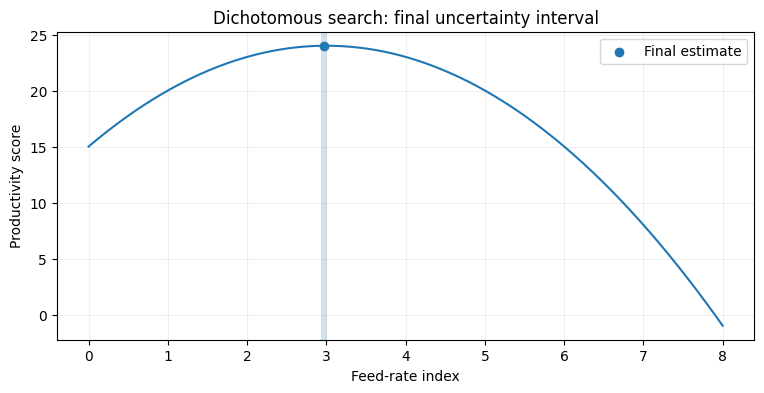

In [2]:
def f1(x): return 24-(x-3)**2
L,R,delta,eps=0.,8.,.02,.10
rows=[]
for k in range(1,100):
    if R-L<=eps: break
    a,b=L,R;x1=(L+R-delta)/2;x2=(L+R+delta)/2
    if f1(x1)>f1(x2): R=x2;decision='discard right'
    elif f1(x1)<f1(x2): L=x1;decision='discard left'
    else: L,R=x1,x2;decision='keep middle'
    rows.append([k,a,b,x1,x2,f1(x1),f1(x2),decision,L,R,R-L])
trace_d=pd.DataFrame(rows,columns=['step','old L','old R','x1','x2','f(x1)','f(x2)','decision','new L','new R','width'])
display(trace_d)
print(f'Final x estimate={(L+R)/2:.6f}, interval [{L:.6f},{R:.6f}], width={R-L:.6f}')
xs=np.linspace(0,8,400)
plt.figure(figsize=(9,4));plt.plot(xs,f1(xs));plt.axvspan(L,R,alpha=.2);plt.scatter([(L+R)/2],[f1((L+R)/2)],label='Final estimate');plt.xlabel('Feed-rate index');plt.ylabel('Productivity score');plt.title('Dichotomous search: final uncertainty interval');plt.legend();plt.grid(alpha=.2);plt.show()
assert R-L<=eps

**Interpretation.** The final bracket is a certificate of *location uncertainty* under the unimodality assumption, not a confidence interval from statistical sampling. The estimated process setting can be compared with the known analytical check $x^*=3$.

## 2. Golden-section search

**Problem.** For the same single-peak machining performance model $f(x)=24-(x-3)^2$ on $[0,8]$, avoid repeatedly evaluating two new trial points. Target a final interval width below $0.10$.

**How the algorithm works.** Define $\rho=(\sqrt 5-1)/2\approx0.618034$. The two trial points are placed so one previously evaluated value can be reused after a bracket reduction:

$$
x_1=R-\rho(R-L),\qquad x_2=L+\rho(R-L).
$$

For maximization, if $f(x_1)<f(x_2)$ move the *left* endpoint to $x_1$; otherwise move the *right* endpoint to $x_2$. After an initial two evaluations, each iteration usually needs only one new evaluation.

**Pseudocode**
```text
INPUT: unimodal f, interval [L,R], tolerance epsilon
rho = (sqrt(5)-1)/2
initialize x1, x2 and evaluate both
WHILE R-L > epsilon:
    IF f(x1)<f(x2):
        L=x1; reuse old x2 as new x1; evaluate new x2
    ELSE:
        R=x2; reuse old x1 as new x2; evaluate new x1
    record bracket, points, comparisons, decision
RETURN midpoint of bracket
```

,step,old L,old R,x1,x2,f(x1),f(x2),decision,new L,new R,width,function calls
0,1,0.00000,8.00000,3.05573,4.94427,23.99689,20.21981,discard right,0.00000,4.94427,4.94427,3
1,2,0.00000,4.94427,1.88854,3.05573,22.76467,23.99689,discard left,1.88854,4.94427,3.05573,4
2,3,1.88854,4.94427,3.05573,3.77709,23.99689,23.39613,discard right,1.88854,3.77709,1.88854,5
3,4,1.88854,3.77709,2.60990,3.05573,23.84782,23.99689,discard left,2.60990,3.77709,1.16718,6
4,5,2.60990,3.77709,3.05573,3.33126,23.99689,23.89026,discard right,2.60990,3.33126,0.72136,7
5,6,2.60990,3.33126,2.88544,3.05573,23.98688,23.99689,discard left,2.88544,3.33126,0.44582,8
6,7,2.88544,3.33126,3.05573,3.16097,23.99689,23.97409,discard right,2.88544,3.16097,0.27553,9
7,8,2.88544,3.16097,2.99068,3.05573,23.99991,23.99689,discard right,2.88544,3.05573,0.17029,10
8,9,2.88544,3.05573,2.95048,2.99068,23.99755,23.99991,discard left,2.95048,3.05573,0.10524,11
9,10,2.95048,3.05573,2.99068,3.01553,23.99991,23.99976,discard right,2.95048,3.01553,0.06504,12


Final x=2.983006; calls=12; interval width=0.065045


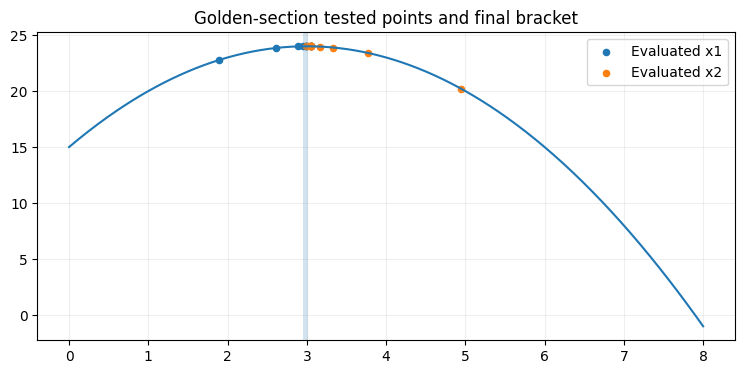

In [3]:
rho=(np.sqrt(5)-1)/2; L,R=0.,8.; a=R-rho*(R-L);b=L+rho*(R-L);fa,fb=f1(a),f1(b)
rows=[]; evals=2
for k in range(1,100):
    if R-L<=.10:break
    oldL,oldR=L,R; aa,bb=a,b;faa,fbb=fa,fb
    if fa<fb:
        L=a;a=b;fa=fb;b=L+rho*(R-L);fb=f1(b);decision='discard left'
    else:
        R=b;b=a;fb=fa;a=R-rho*(R-L);fa=f1(a);decision='discard right'
    evals+=1;rows.append([k,oldL,oldR,aa,bb,faa,fbb,decision,L,R,R-L,evals])
gold=pd.DataFrame(rows,columns=['step','old L','old R','x1','x2','f(x1)','f(x2)','decision','new L','new R','width','function calls'])
display(gold)
print(f'Final x={(L+R)/2:.6f}; calls={evals}; interval width={R-L:.6f}')
plt.figure(figsize=(9,4));plt.plot(xs,f1(xs));plt.scatter(gold['x1'],gold['f(x1)'],s=20,label='Evaluated x1');plt.scatter(gold['x2'],gold['f(x2)'],s=20,label='Evaluated x2');plt.axvspan(L,R,alpha=.2);plt.grid(alpha=.2);plt.legend();plt.title('Golden-section tested points and final bracket');plt.show()
assert R-L<=.10

**Interpretation.** Both direct searches reduce a one-dimensional uncertainty interval. The golden-section reuse property reduces repeated function evaluations, which matters when each objective evaluation requires an expensive simulation.

## 3. Gradient method — steepest ascent with exact line search

**Problem.** Choose two continuous production-control settings $x_1$ and $x_2$ to maximize a differentiable response surface. The numerical example is

$$
\max f(x_1,x_2)=4x_1+6x_2-2x_1^2-2x_1x_2-2x_2^2.
$$

Start from $\mathbf x^{(0)}=(1,1)$. The gradient and Hessian are

$$
\nabla f(\mathbf x)=\begin{bmatrix}4-4x_1-2x_2\\6-2x_1-4x_2\end{bmatrix},\qquad H=\begin{bmatrix}-4&-2\\-2&-4\end{bmatrix}.
$$

The Hessian has eigenvalues $-6$ and $-2$, so the model is strictly concave and any stationary point is the unique global maximum. Solving $\nabla f=0$ gives $x_1^*=1/3$ and $x_2^*=4/3$.

**How it works.** At iteration $k$, move in the gradient direction $\mathbf d_k=\nabla f(\mathbf x_k)$, using an exact one-dimensional line search to choose $\alpha_k$:

$$
\mathbf x_{k+1}=\mathbf x_k+\alpha_k\mathbf d_k,
\qquad
\alpha_k=-\frac{\mathbf d_k^T\mathbf d_k}{\mathbf d_k^TH\mathbf d_k}.
$$

The step formula follows from differentiating the quadratic $f(\mathbf x_k+\alpha\mathbf d_k)$ with respect to $\alpha$. The denominator is negative for every nonzero direction.

**Pseudocode**
```text
INPUT: f, gradient, Hessian, start x0, tolerance
REPEAT:
    g = gradient(x)
    IF ||g|| < tolerance: STOP
    d = g
    alpha = -(d dot d)/(d transpose H d)
    x_new = x + alpha*d
    evaluate f(x_new), record line-search calculation
    x = x_new
UNTIL stationary tolerance or iteration limit
OUTPUT: final x, objective, full iteration history
```

,iter,old x1,old x2,grad x1,grad x2,grad norm,gTg,gTHg,step alpha,new x1,new x2,old f,new f,next-gradient dot previous
0,0,1.00000,1.00000,-2.00000e+00,0.00000e+00,2.00000e+00,4.00000e+00,-1.60000e+01,0.25,0.50000,1.00000,4.00000,4.50000,0.0
1,1,0.50000,1.00000,0.00000e+00,1.00000e+00,1.00000e+00,1.00000e+00,-4.00000e+00,0.25,0.50000,1.25000,4.50000,4.62500,0.0
2,2,0.50000,1.25000,-5.00000e-01,0.00000e+00,5.00000e-01,2.50000e-01,-1.00000e+00,0.25,0.37500,1.25000,4.62500,4.65625,0.0
3,3,0.37500,1.25000,0.00000e+00,2.50000e-01,2.50000e-01,6.25000e-02,-2.50000e-01,0.25,0.37500,1.31250,4.65625,4.66406,0.0
4,4,0.37500,1.31250,-1.25000e-01,0.00000e+00,1.25000e-01,1.56250e-02,-6.25000e-02,0.25,0.34375,1.31250,4.66406,4.66602,0.0
5,5,0.34375,1.31250,0.00000e+00,6.25000e-02,6.25000e-02,3.90625e-03,-1.56250e-02,0.25,0.34375,1.32812,4.66602,4.66650,0.0
6,6,0.34375,1.32812,-3.12500e-02,0.00000e+00,3.12500e-02,9.76562e-04,-3.90625e-03,0.25,0.33594,1.32812,4.66650,4.66663,0.0
7,7,0.33594,1.32812,0.00000e+00,1.56250e-02,1.56250e-02,2.44141e-04,-9.76562e-04,0.25,0.33594,1.33203,4.66663,4.66666,0.0
8,8,0.33594,1.33203,-7.81250e-03,0.00000e+00,7.81250e-03,6.10352e-05,-2.44141e-04,0.25,0.33398,1.33203,4.66666,4.66666,0.0
9,9,0.33398,1.33203,0.00000e+00,3.90625e-03,3.90625e-03,1.52588e-05,-6.10352e-05,0.25,0.33398,1.33301,4.66666,4.66667,0.0


Computed optimum: [0.33333 1.33333] objective 4.666666666666666 analytic optimum (0.3333333333333333, 1.3333333333333333)


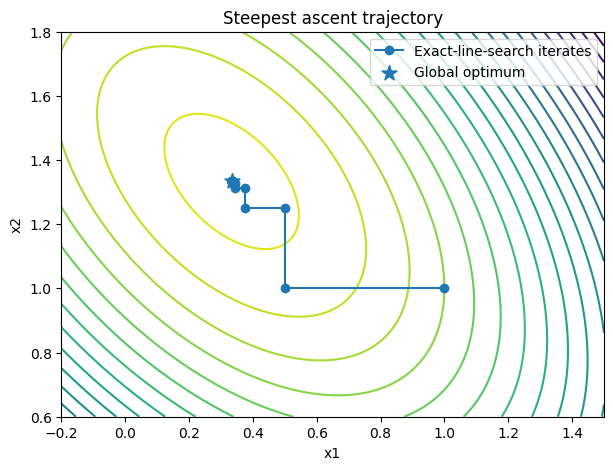

In [4]:
H=np.array([[-4.,-2.],[-2.,-4.]])
def f2(v): x,y=v;return 4*x+6*y-2*x*x-2*x*y-2*y*y
def grad2(v): x,y=v;return np.array([4-4*x-2*y,6-2*x-4*y])
x=np.array([1.,1.]); steps=[x.copy()]; rows=[]
for k in range(25):
    g=grad2(x);normg=np.linalg.norm(g)
    if normg<1e-7:break
    numerator=g@g; denominator=g@H@g; alpha=-numerator/denominator
    new=x+alpha*g
    rows.append([k,*x,*g,normg,numerator,denominator,alpha,*new,f2(x),f2(new),grad2(new)@g])
    x=new;steps.append(x.copy())
df=pd.DataFrame(rows,columns=['iter','old x1','old x2','grad x1','grad x2','grad norm','gTg','gTHg','step alpha','new x1','new x2','old f','new f','next-gradient dot previous'])
display(df)
print('Computed optimum:',x,'objective',f2(x),'analytic optimum',(1/3,4/3))
xx,yy=np.meshgrid(np.linspace(-.2,1.5,160),np.linspace(.6,1.8,160));zz=4*xx+6*yy-2*xx**2-2*xx*yy-2*yy**2
plt.figure(figsize=(7,5));plt.contour(xx,yy,zz,levels=25);steps=np.array(steps);plt.plot(steps[:,0],steps[:,1],'o-',label='Exact-line-search iterates');plt.scatter([1/3],[4/3],marker='*',s=130,label='Global optimum');plt.xlabel('x1');plt.ylabel('x2');plt.legend();plt.title('Steepest ascent trajectory');plt.show()
assert np.linalg.norm(x-np.array([1/3,4/3]))<1e-4

**Interpretation.** For the quadratic model, successive exact-line-search gradients are perpendicular (up to numerical precision). The objective increases each iteration. An unconstrained gradient method alone does not enforce resource limits; constrained variants are demonstrated below.

## 4. Separable programming — piecewise-linear approximation

**Problem.** Two production lines have diminishing net contributions $f_1(x_1)=12x_1-x_1^2$ and $f_2(x_2)=10x_2-0.5x_2^2$. A shared machine can process at most $8$ units. Choose $0\le x_1,x_2\le8$ to maximize

$$
\max\;12x_1-x_1^2+10x_2-\frac12x_2^2
$$
$$
\text{subject to }x_1+x_2\le8,\quad0\le x_1,x_2\le8.
$$

**How the algorithm works.** Each single-variable nonlinear contribution is approximated using line segments connecting breakpoints $a_k$. For $x_j$, the piecewise-linear representation is

$$
x_j=\sum_k a_k\lambda_{jk},\qquad \tilde f_j=\sum_k f_j(a_k)\lambda_{jk},\qquad\sum_k\lambda_{jk}=1.
$$

Only two adjacent breakpoint weights may be positive. This is enforced through segment-selection binary variables. For these **concave contributions and a maximization objective**, an LP convex-combination model using all breakpoints already has a correct piecewise-linear concave envelope; its optimal solution uses adjacent active breakpoints, so explicit binary variables are unnecessary here. For general nonconcave functions, explicit adjacency constraints (SOS2 or binaries) are needed.

**Pseudocode**
```text
INPUT: individual nonlinear functions, bounds, resource capacity, mesh
FOR each variable: compute breakpoint coordinates and function values
CREATE nonnegative convex-combination weights lambda
ADD: one weight-sum equation per variable
ADD: shared resource limit using weighted breakpoint quantities
MAXIMIZE: sum of weighted breakpoint objective values
SOLVE linear approximation
RECONSTRUCT quantities, compute true nonlinear objective, compare to NLP solve
REPEAT with finer mesh to check approximation error
```

,breakpoint spacing,x1,x2,LP approximated objective,actual objective,gap to continuous optimum,active x1 weights,active x2 weights
0,4.00,4.00,4.00,64.00000,64.00000,0.66667,"[(4.0, 1.0)]","[(4.0, 1.0)]"
1,2.00,4.00,4.00,64.00000,64.00000,0.66667,"[(4.0, 1.0)]","[(4.0, 1.0)]"
2,1.00,3.00,5.00,64.50000,64.50000,0.16667,"[(3.0, 1.0)]","[(5.0, 1.0)]"
3,0.50,3.50,4.50,64.62500,64.62500,0.04167,"[(3.5, 1.0)]","[(4.5, 1.0)]"
4,0.25,3.25,4.75,64.65625,64.65625,0.01042,"[(3.25, 1.0)]","[(4.75, 1.0)]"


Nonlinear reference: [3.33333 4.66667] objective 64.6666666666666


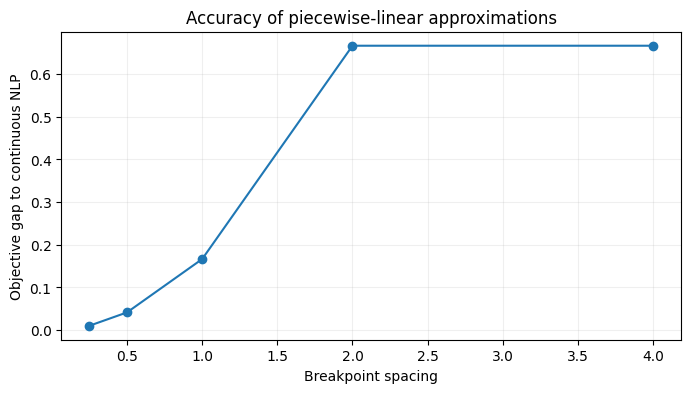

In [5]:
def sepvalue(x):return 12*x[0]-x[0]**2+10*x[1]-.5*x[1]**2
ref=minimize(lambda x:-sepvalue(x),[4.,4.],bounds=[(0,8)]*2,constraints=[{'type':'ineq','fun':lambda x:8-sum(x)}],method='SLSQP',options={'ftol':1e-12})
rows=[]
for step in [4.,2.,1.,.5,.25]:
    bp=np.arange(0,8+step/2,step);m=len(bp)
    cvec=-np.r_[12*bp-bp*bp,10*bp-.5*bp*bp]
    Aeq=np.zeros((2,2*m));Aeq[0,:m]=1;Aeq[1,m:]=1
    Aub=np.r_[bp,bp].reshape(1,-1)
    sol=linprog(cvec,A_ub=Aub,b_ub=[8.],A_eq=Aeq,b_eq=[1,1],bounds=(0,None),method='highs')
    assert sol.success
    w1,w2=sol.x[:m],sol.x[m:];v=np.array([bp@w1,bp@w2]);rows.append([step,*v,-sol.fun,sepvalue(v),ref.fun*-1-sepvalue(v),[(float(bp[i]),float(w1[i])) for i in range(m) if w1[i]>1e-7],[(float(bp[i]),float(w2[i])) for i in range(m) if w2[i]>1e-7]])
results=pd.DataFrame(rows,columns=['breakpoint spacing','x1','x2','LP approximated objective','actual objective','gap to continuous optimum','active x1 weights','active x2 weights']);display(results)
print('Nonlinear reference:',ref.x,'objective',-ref.fun)
plt.figure(figsize=(8,4));plt.plot(results['breakpoint spacing'],results['gap to continuous optimum'],'o-');plt.xlabel('Breakpoint spacing');plt.ylabel('Objective gap to continuous NLP');plt.title('Accuracy of piecewise-linear approximations');plt.grid(alpha=.2);plt.show()
assert results['gap to continuous optimum'].min()>=-1e-6

**Interpretation.** The printed active weights identify the two breakpoints interpolated for each production line. Smaller spacing generally improves objective approximation but requires more model variables. The last column measures *true* nonlinear loss relative to the continuous reference solution.

## 5. Quadratic programming — constrained resource allocation

**Problem.** A factory divides production between two product families. After accounting for diminishing contribution, the net profit (in consistent monetary units) is

$$
\max\; p(x_1,x_2)=10x_1+8x_2-x_1^2-x_2^2
$$

subject to capacity and minimum-order requirements:

$$
2x_1+x_2\le 8,\qquad x_1+x_2\ge3,\qquad x_1,x_2\ge0.
$$

**How it works.** Quadratic programming optimizes a quadratic objective under linear constraints. Write minimization as

$$
\min\frac12\mathbf x^TQ\mathbf x+\mathbf c^T\mathbf x,
\quad Q=\begin{bmatrix}2&0\\0&2\end{bmatrix},\quad \mathbf c=\begin{bmatrix}-10\\-8\end{bmatrix}.
$$

Since $Q\succ0$, the minimization objective is strictly convex; the global optimum is unique. The KKT approach combines stationarity, primal feasibility, dual feasibility, and complementary slackness. To expose every **candidate active-set test**, enumerate candidate binding inequalities, solve stationarity systems, and reject infeasible or negative-multiplier cases.

**Pseudocode**
```text
INPUT: positive-definite Q, c, linear inequalities A x <= b
FOR every potential active subset of constraints:
    solve [Q A_active^T; A_active 0] [x;lambda]=[-c;b_active]
    test all primal inequalities A x<=b
    test multipliers lambda>=0 for active inequalities
    calculate objective and record accept/reject reason
SELECT feasible candidate with smallest minimization objective
CROSS-CHECK numerical quadratic optimization
```

,assumed active,x1,x2,minimum slack,KKT equation residual,multipliers,primal feasible,dual feasible,valid KKT,profit
0,(none),5.00000e+00,4.00000e+00,-6.00000e+00,0.00000e+00,[],False,True,False,4.10000e+01
1,machine,2.60000e+00,2.80000e+00,5.32907e-15,1.03579e-14,[2.399999999999998],True,True,True,3.38000e+01
2,minimum order,2.00000e+00,1.00000e+00,-2.66454e-15,4.78299e-15,[-6.0],True,False,False,2.30000e+01
3,x1 >= 0,1.23393e-16,4.00000e+00,1.23393e-16,1.23393e-16,[-10.0],True,False,False,1.60000e+01
4,x2 >= 0,5.00000e+00,-3.47697e-16,-2.00000e+00,2.68713e-15,[-7.999999999999998],False,False,False,2.50000e+01
5,"machine,minimum order",5.00000e+00,-2.00000e+00,-2.00000e+00,1.05465e-14,"[-11.999999999999996, -23.999999999999996]",False,False,False,5.00000e+00
6,"machine,x1 >= 0",-2.14941e-15,8.00000e+00,-2.14941e-15,1.47249e-14,"[-7.999999999999991, -25.99999999999998]",True,False,False,-3.55271e-14
7,"machine,x2 >= 0",4.00000e+00,-2.22045e-16,-5.32907e-15,5.89569e-15,"[0.9999999999999982, -7.0000000000000036]",True,False,False,2.40000e+01
8,"minimum order,x1 >= 0",-4.21536e-16,3.00000e+00,-4.21536e-16,6.55541e-15,"[-1.9999999999999907, -8.000000000000007]",True,False,False,1.50000e+01
9,"minimum order,x2 >= 0",3.00000e+00,-4.44089e-16,-4.44089e-16,4.37377e-15,"[-4.0, -3.9999999999999987]",True,False,False,2.10000e+01


KKT optimum (np.float64(33.79999999999998), array([2.6, 2.8])) SLSQP [2.6 2.8] 33.80000000000017


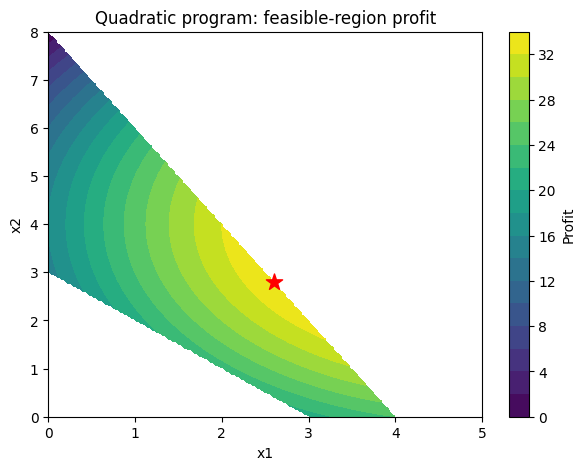

In [6]:
import itertools
Q=2*np.eye(2); cc=np.array([-10.,-8.])
A=np.array([[2,1],[-1,-1],[-1,0],[0,-1]],float);b=np.array([8.,-3.,0.,0.]);labels=['machine','minimum order','x1 >= 0','x2 >= 0']
rr=[];candidates=[]
for q in range(4):
    for subset in itertools.combinations(range(4),q):
        Aact=A[list(subset)] if subset else np.zeros((0,2)); k=len(subset)
        K=np.block([[Q,Aact.T],[Aact,np.zeros((k,k))]]);rhs=np.r_[-cc,b[list(subset)]]
        v=np.linalg.lstsq(K,rhs,rcond=None)[0]; x=v[:2];lam=v[2:]
        residual=np.linalg.norm(K@v-rhs)
        feas=bool(np.all(A@x<=b+1e-7))
        dual=bool(np.all(lam>=-1e-7))
        valid=feas and dual and residual<1e-7
        profit=10*x[0]+8*x[1]-x@x
        rr.append([','.join(labels[i] for i in subset) or '(none)',*x,*( [float(np.min(b-A@x))]),residual,lam.tolist(),feas,dual,valid,profit])
        if valid:candidates.append((profit,x))
active=pd.DataFrame(rr,columns=['assumed active','x1','x2','minimum slack','KKT equation residual','multipliers','primal feasible','dual feasible','valid KKT','profit']);display(active)
res=minimize(lambda x:x@x-10*x[0]-8*x[1],x0=[2,3],jac=lambda x:2*x-np.array([10.,8.]),bounds=[(0,None)]*2,constraints=[{'type':'ineq','fun':lambda x:8-2*x[0]-x[1]},{'type':'ineq','fun':lambda x:x.sum()-3}],method='SLSQP',options={'ftol':1e-12})
best=max(candidates,key=lambda t:t[0]);print('KKT optimum',best,'SLSQP',res.x,-res.fun)
xx,yy=np.meshgrid(np.linspace(0,5,220),np.linspace(0,8,220));mask=(2*xx+yy<=8)&(xx+yy>=3)
zz=np.where(mask,10*xx+8*yy-xx*xx-yy*yy,np.nan)
plt.figure(figsize=(7,5));plt.contourf(xx,yy,zz,levels=20);plt.colorbar(label='Profit');plt.scatter([best[1][0]],[best[1][1]],c='red',marker='*',s=150);plt.xlabel('x1');plt.ylabel('x2');plt.title('Quadratic program: feasible-region profit');plt.show()
assert np.linalg.norm(best[1]-res.x)<1e-4

**Interpretation.** Each active-set trial shows the equations solved, the candidate decision, feasibility status, and multiplier sign test. Because the objective is strictly concave in its maximization form, a valid KKT point is the unique optimum.

## 6. Chance-constrained programming — uncertain material demand

**Problem.** A processing facility chooses a daily production quantity $x$ while raw-material consumption per unit is uncertain. The consumption coefficient $A$ is normally distributed with mean $2$ kg/unit and standard deviation $0.25$ kg/unit. The facility has $120$ kg of material. Find the maximum production quantity subject to at least a 95% probability that available material is sufficient:

$$
\max x\quad\text{subject to}\quad\Pr(Ax\le120)\ge0.95,\qquad x\ge0.
$$

**How the algorithm works.** Because $x\ge0$ and $A\sim N(2,0.25^2)$, material usage $Ax$ is normal with mean $2x$ and standard deviation $0.25x$. The probability condition has the deterministic equivalent

$$
2x+z_{0.95}(0.25x)\le120,
\qquad z_{0.95}=\Phi^{-1}(0.95)\approx1.644854.
$$

This formula assumes the stated normal model and known mean and variance. It is not distribution-free.

**Pseudocode**
```text
INPUT: coefficient mean mu, std sigma, available capacity b, reliability p
COMPUTE z = inverse_normal_cdf(p)
REPLACE chance constraint by (mu+z*sigma)*x <= b (when x>=0)
SOLVE deterministic optimization for x
COMPUTE achieved reliability using the original probability model
SWEEP reliability levels and plot feasible production quantities
```

,required reliability,normal quantile,protected material per unit,maximum output,achieved reliability,expected unused material
0,0.500,0.00000,2.00000,60.00000,0.500,0.00000
1,0.800,0.84162,2.21041,54.28869,0.800,11.42263
2,0.900,1.28155,2.32039,51.71549,0.900,16.56902
3,0.950,1.64485,2.41121,49.76747,0.950,20.46505
4,0.975,1.95996,2.48999,48.19295,0.975,23.61411
5,0.990,2.32635,2.58159,46.48304,0.990,27.03393
6,0.999,3.09023,2.77256,43.28133,0.999,33.43734


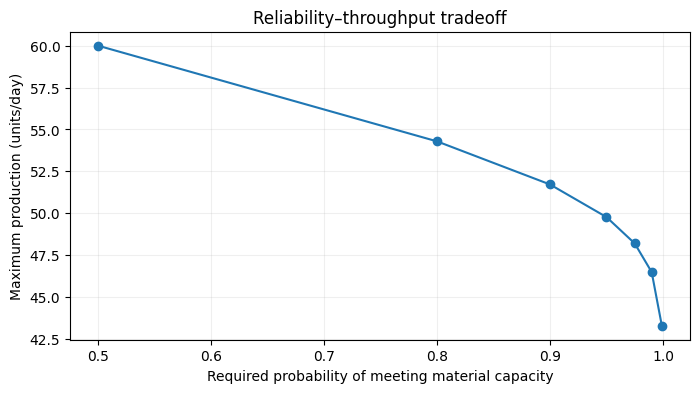

In [7]:
mu,sigma,cap=2.,.25,120.
rows=[]
for level in [.50,.80,.90,.95,.975,.99,.999]:
    z=norm.ppf(level); x=cap/(mu+z*sigma)
    achieved=norm.cdf((cap/x-mu)/sigma)
    rows.append([level,z,mu+z*sigma,x,achieved,cap-mu*x])
chance=pd.DataFrame(rows,columns=['required reliability','normal quantile','protected material per unit','maximum output','achieved reliability','expected unused material']);display(chance)
plt.figure(figsize=(8,4));plt.plot(chance['required reliability'],chance['maximum output'],'o-');plt.xlabel('Required probability of meeting material capacity');plt.ylabel('Maximum production (units/day)');plt.title('Reliability–throughput tradeoff');plt.grid(alpha=.2);plt.show()
assert abs(chance.loc[3,'achieved reliability']-.95)<1e-10

**Interpretation.** Higher reliability requires a larger safety margin and therefore reduces allowable throughput. The difference between material capacity and expected usage is *not* the same as a guaranteed safety reserve; the probability guarantee is conditional on the assumed normal distribution.

## 7. Linear-combinations method — feasible-direction optimization

**Problem.** A production planner allocates a fixed total of 8 labor blocks between operations 1 and 2. The objective is to maximize concave operating contribution:

$$
\max f(x_1,x_2)=12x_1-x_1^2+10x_2-\tfrac12x_2^2
$$
$$
\text{subject to }x_1+x_2=8,\quad x_1,x_2\ge0.
$$

**How it works.** Represent every feasible choice as a convex combination of the simplex vertices $(8,0)$ and $(0,8)$. Starting at a feasible point, solve a *linearized* subproblem using the objective gradient to select a vertex $\mathbf v_k$:

$$
\mathbf v_k\in\arg\max_{\mathbf v\in\mathcal F}\nabla f(\mathbf x_k)^T\mathbf v.
$$

Then move along the feasible line segment to improve the true objective:

$$
\mathbf x_{k+1}=(1-\alpha_k)\mathbf x_k+\alpha_k\mathbf v_k,\quad0\le\alpha_k\le1.
$$

This is a feasible-direction / conditional-gradient (Frank–Wolfe) implementation of the linear-combinations principle. The linearized improvement gap $\nabla f(\mathbf x_k)^T(\mathbf v_k-\mathbf x_k)$ is the stopping measure.

**Pseudocode**
```text
INPUT: feasible x0, feasible vertices, tolerance
REPEAT:
    compute gradient g at current x
    choose vertex v maximizing dot(g,v)
    set feasible direction d = v-x
    calculate gap = dot(g,d)
    IF gap<=tolerance: STOP
    find alpha in [0,1] maximizing f(x+alpha*d)
    update x = x+alpha*d
    record vertex, gap, step, objective
OUTPUT: feasible optimum estimate and full history
```

,step,old x1,old x2,grad x1,grad x2,vertex 1 score,vertex 2 score,chosen v1,chosen v2,linearized gap,step alpha,new x1,new x2,old profit,new profit
0,0,8.0,0.0,-4.0,10.0,-32.0,80.0,0.0,8.0,112.0,0.58333,3.33333,4.66667,32.0,64.66667


Feasible-direction optimum: [3.33333 4.66667] profit 64.66666666666669 optimality gap 3.552713678800501e-15


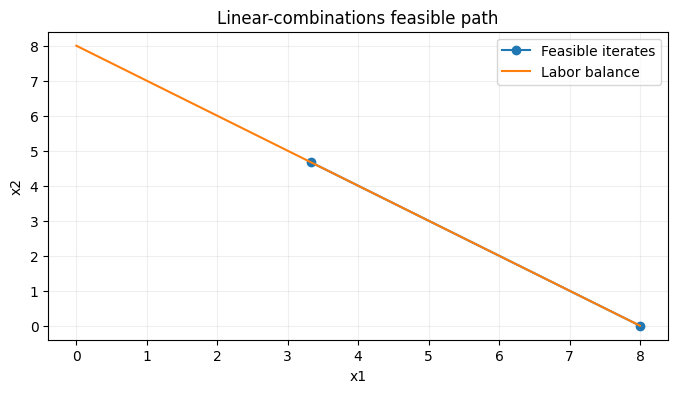

In [8]:
def fw_f(v):return 12*v[0]-v[0]**2+10*v[1]-.5*v[1]**2
def fw_g(v):return np.array([12-2*v[0],10-v[1]])
vertices=np.array([[8.,0.],[0.,8.]])
x=np.array([8.,0.]);rows=[];path=[x.copy()]
for k in range(40):
    g=fw_g(x);scores=vertices@g;v=vertices[np.argmax(scores)];d=v-x;gap=g@d
    if gap<1e-9:break
    curvature=2*d[0]**2+d[1]**2
    alpha=np.clip(gap/curvature,0,1) if curvature>0 else 0
    new=x+alpha*d
    rows.append([k,*x,*g,*scores,*v,gap,alpha,*new,fw_f(x),fw_f(new)])
    x=new;path.append(x.copy())
fw=pd.DataFrame(rows,columns=['step','old x1','old x2','grad x1','grad x2','vertex 1 score','vertex 2 score','chosen v1','chosen v2','linearized gap','step alpha','new x1','new x2','old profit','new profit']);display(fw)
print('Feasible-direction optimum:',x,'profit',fw_f(x),'optimality gap',fw_g(x)@(vertices[np.argmax(vertices@fw_g(x))]-x))
pp=np.array(path);plt.figure(figsize=(8,4));plt.plot(pp[:,0],pp[:,1],'o-',label='Feasible iterates');plt.plot([0,8],[8,0],label='Labor balance');plt.xlabel('x1');plt.ylabel('x2');plt.title('Linear-combinations feasible path');plt.grid(alpha=.2);plt.legend();plt.show()
assert abs(x.sum()-8)<1e-9

**Interpretation.** Every iterate preserves labor balance automatically because it is a convex combination of feasible choices. The gap column reports potential *first-order* improvement from moving toward the best linearized vertex. A small gap supports stopping under the concavity assumption.

## 8. SUMT — sequential unconstrained minimization technique

**Problem.** Two operating levels minimize a convex penalty for deviating from preferred settings $(4,3)$, but machine capacity limits their weighted use:

$$
\min f(x_1,x_2)=(x_1-4)^2+(x_2-3)^2
$$
$$
\text{subject to }2x_1+x_2\le7,\quad x_1,x_2\ge0.
$$

**How the algorithm works.** Replace constrained minimization with a *sequence* of unconstrained problems using an exterior quadratic penalty:

$$
F_r(\mathbf x)=f(\mathbf x)+r\bigl[\max(0,2x_1+x_2-7)^2+\max(0,-x_1)^2+\max(0,-x_2)^2\bigr].
$$

The penalty coefficient $r$ increases each outer iteration. Constraint violations become progressively more costly; for finite $r$, the penalized minimizer can still be infeasible. This example uses an exterior SUMT formulation (not the logarithmic interior barrier variant).

**Pseudocode**
```text
INPUT: nonlinear objective, constraints g_i(x)<=0, start x, penalty schedule
FOR penalties r = 1, 10, 100, ...:
    define F_r(x)=f(x)+r*sum(max(0,g_i(x))^2)
    minimize F_r numerically, initialized at previous solution
    compute original f(x), violation of each constraint, penalized F_r(x)
    record all outer iterations and inner solver iteration counts
STOP when maximum violation and step changes satisfy tolerances
CROSS-CHECK using directly constrained optimizer
```

,penalty r,start x1,start x2,new x1,new x2,original objective,machine violation,x1 nonneg violation,x2 nonneg violation,max violation,penalized objective,inner iterations
0,0.1,4.00000,3.00000,3.46667,2.73333,0.35556,2.66667e+00,0.0,0.0,2.66667e+00,1.06667,3
1,1.0,3.46667,2.73333,2.66667,2.33333,2.22222,6.66667e-01,0.0,0.0,6.66667e-01,2.66667,3
2,10.0,2.66667,2.33333,2.43137,2.21569,3.07574,7.84314e-02,0.0,0.0,7.84314e-02,3.13725,5
3,100.0,2.43137,2.21569,2.40319,2.20160,3.18724,7.98402e-03,0.0,0.0,7.98402e-03,3.19361,3
4,1000.0,2.40319,2.20160,2.40032,2.20016,3.19872,7.99830e-04,0.0,0.0,7.99830e-04,3.19936,3
5,10000.0,2.40032,2.20016,2.40001,2.20006,3.19987,7.99866e-05,0.0,0.0,7.99866e-05,3.19994,3
6,100000.0,2.40001,2.20006,2.39985,2.20030,3.19999,7.95056e-06,0.0,0.0,7.95056e-06,3.19999,2


SUMT last iterate [2.39985 2.2003 ] directly constrained optimum [2.4 2.2] original objective 3.200000000000001


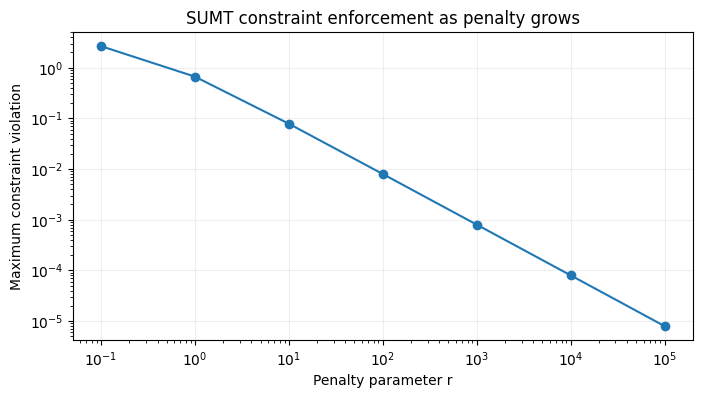

In [9]:
def base(v):return (v[0]-4)**2+(v[1]-3)**2
def violations(v):return np.maximum([2*v[0]+v[1]-7,-v[0],-v[1]],0)
def penalty(v,r):return base(v)+r*np.sum(violations(v)**2)
start=np.array([4.,3.]);rows=[];history=[]
for r in [0.1,1.,10.,100.,1000.,10000.,100000.]:
    out=minimize(lambda z:penalty(z,r),start,method='BFGS',options={'gtol':1e-9,'maxiter':500});v=out.x
    rows.append([r,*start,*v,base(v),*violations(v),max(violations(v)),penalty(v,r),out.nit])
    history.append(v.copy());start=v
sumt=pd.DataFrame(rows,columns=['penalty r','start x1','start x2','new x1','new x2','original objective','machine violation','x1 nonneg violation','x2 nonneg violation','max violation','penalized objective','inner iterations']);display(sumt)
reference=minimize(base,[2.,3.],method='SLSQP',bounds=[(0,None)]*2,constraints=[{'type':'ineq','fun':lambda z:7-2*z[0]-z[1]}],options={'ftol':1e-12})
print('SUMT last iterate',start,'directly constrained optimum',reference.x,'original objective',reference.fun)
plt.figure(figsize=(8,4));plt.loglog(sumt['penalty r'],sumt['max violation'],'o-');plt.xlabel('Penalty parameter r');plt.ylabel('Maximum constraint violation');plt.grid(alpha=.2);plt.title('SUMT constraint enforcement as penalty grows');plt.show()
assert np.linalg.norm(start-reference.x)<1e-3

**Interpretation.** The output distinguishes penalized objective, original objective, and violation. They must not be confused: during early penalty iterations the point is not necessarily feasible. The converged result is checked against a direct constrained solve. Large penalties may make numerical minimization ill-conditioned, so infinitely large penalties are not practical.

## 9. Verification and method selection

| Algorithm | Required information | Decision at each iteration | Numerical output to inspect | Important limitation |
|---|---|---|---|---|
| Dichotomous | Unimodal 1-D function | Compare closely spaced values | Bracket endpoints and width | Requires unimodality |
| Golden-section | Unimodal 1-D function | Retain better subinterval | Evaluation count and width | Can find local peak otherwise |
| Steepest ascent | Smooth gradient | Direction and line-search step | Gradient norm, objective, path | Stationarity alone is not global optimality |
| Separable programming | Additive nonlinear functions | Breakpoint weights | Approximation error and active segments | General nonconcave cases require adjacency enforcement |
| Quadratic programming | Quadratic objective, linear constraints | Test active constraints and KKT multipliers | Feasible candidate and multipliers | Global optimality requires convex/concave structure |
| Chance constraints | Probability distribution assumptions | Convert probabilistic limit | Achieved probability and capacity | Sensitive to distributional assumptions |
| Linear combinations | Linearizable feasible set | Best gradient-directed feasible vertex | Gap, chosen vertex, line-search step | Nonconvex objectives lack global guarantee |
| SUMT | Penalty schedule and numerical minimizer | Increase constraint-violation penalty | Original cost vs violation | Large penalties can be ill-conditioned |

**Reproducibility checks.** The notebook uses deterministic datasets and fixed algebraic formulations. Numerical references are independently computed where appropriate. Plots are generated directly from the iteration traces; they are not manually sketched results.

**Chapter scope note.** The quadratic-programming chapter section also treats specialized simplex-based quadratic methods, while the separable chapter section develops explicit mixed-integer adjacency formulations. The present notebook focuses on complete, runnable conceptual implementations of these topics rather than reproducing the specialized legacy tableaux verbatim.